# Correcting for network bias

The scores an [attribution](../concepts/#attribution) method gives
the nodes of a
[knowledge-primed neural network](../concepts/#kpnn) (KPNN) depend
partly on where each node sits in the [graph](../concepts/#graph):
a node that pools many inputs can score high because it pools many
inputs. The literature calls this network bias, or structural
bias. It matters when you read node scores as a ranking of nodes;
the model's predictions are not affected. Several papers correct
for it, each in its own way, and whether to correct at all is an
open question.

This page shows how to measure the effect and how to try the
published corrections with `kpnn2`. It does not recommend one; the
section "Before you correct" says what to check before you trust a
corrected score. The page builds on
[Attributions by node name](../map-node-attributions/), which explains
how scores get node names, and on the model of the
[Feedforward example](../feedforward-example/).

## Setup

The scores come from Captum, which is not a `kpnn2` dependency:

```bash
pip install captum
```

Graphviz is used only to draw the toy graph.

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr
from captum.attr import LayerConductance
from torch import nn

import kpnn2

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

## A toy network

Twenty-four genes feed ten pathways, and every pathway feeds one
outcome node. The pathways differ only in size, from 2 to 16 member
genes drawn at random, so some genes sit in several pathways. A
gene that joins no pathway is not an input node, and
`align_inputs()` ignores its column.

`node_table()` gives one row of graph counts per
[node](../concepts/#node). For a pathway, `in_degree` is its number
of member genes, and here it equals `n_input_ancestors`, the inputs
that reach it.

In [ ]:
genes = [f"gene_{index:02d}" for index in range(1, 25)]
pathway_sizes = {
    "pathway_a": 2,
    "pathway_b": 3,
    "pathway_c": 3,
    "pathway_d": 4,
    "pathway_e": 5,
    "pathway_f": 6,
    "pathway_g": 8,
    "pathway_h": 10,
    "pathway_i": 12,
    "pathway_j": 16,
}
rng = np.random.default_rng(42)
rows = []
for pathway, size in pathway_sizes.items():
    members = rng.choice(
        genes,
        size=size,
        replace=False,
    )
    rows += [(str(gene), pathway) for gene in members]
rows += [(pathway, "outcome") for pathway in pathway_sizes]
edgelist = pd.DataFrame(
    rows,
    columns=["source", "target"],
)

spec = kpnn2.parse_layered(edgelist)
counts = spec.node_table()
pathways = list(spec.layer_nodes[1])
counts.loc[pathways, ["layer", "in_degree", "n_input_ancestors"]]

,layer,in_degree,n_input_ancestors
node,,,
pathway_a,1,2,2
pathway_b,1,3,3
pathway_c,1,3,3
pathway_d,1,4,4
pathway_e,1,5,5
pathway_f,1,6,6
pathway_g,1,8,8
pathway_h,1,10,10
pathway_i,1,12,12


The drawing shows the graph: genes on the left, each pathway
with its number of member genes in the middle, and the outcome on
the right.

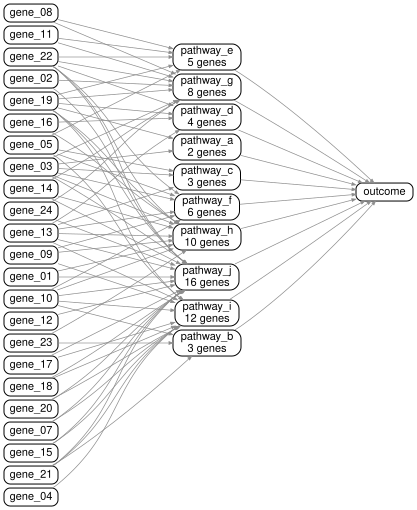

In [ ]:
from graphviz import Digraph

drawing = Digraph()
drawing.attr(
    rankdir="LR",
    ranksep="1.6",
    nodesep="0.06",
)
drawing.attr(
    "node",
    fontname="Helvetica",
    fontsize="11",
    shape="box",
    style="rounded",
    height="0.25",
    margin="0.06,0.02",
)
drawing.attr(
    "edge",
    color="#8c8c8c",
    arrowsize="0.4",
    penwidth="0.7",
)
for layer, names in enumerate(spec.layer_nodes):
    with drawing.subgraph() as same_layer:
        same_layer.attr(rank="same")
        for name in names:
            label = name
            if name in pathways:
                label = f"{name}\n{counts.loc[name, 'in_degree']} genes"
            same_layer.node(
                name,
                label,
            )
for source, target in edgelist.itertuples(index=False):
    drawing.edge(
        source,
        target,
    )
drawing

## Model and scores

The model has one `PackedLinear` per [hop](../concepts/#hop) —
everything entering one layer — and a tanh between them: genes to
pathways, then pathways to the outcome. `pathway_scores()` trains
one run and scores the pathways with Captum's `LayerConductance` on
the first hop module. `map_node_attributions()` names the scores,
and the function returns each pathway's mean absolute score over
the observations.

Each run uses its seed for the simulated data and for
`generator=`, so runs differ only by chance. `simulate()` draws
standard normal genes and adds 1 to the informative genes in
class 1.

In [ ]:
class PathwayModel(nn.Module):
    def __init__(
        self,
        spec,
        generator,
    ):
        super().__init__()
        self.hops = nn.ModuleList(
            [
                kpnn2.PackedLinear.from_hop(
                    hop,
                    identity=spec.fingerprint,
                    generator=generator,
                )
                for hop in spec.hops
            ]
        )

    def forward(self, x):
        pathway_state = torch.tanh(self.hops[0](x))
        return self.hops[1](pathway_state)


def simulate(
    informative_genes,
    seed,
    n_samples=1000,
):
    """Standard normal genes; informative genes gain 1 in class 1."""
    rng = np.random.default_rng(seed)
    labels = rng.integers(
        0,
        2,
        size=n_samples,
    )
    values = rng.normal(
        0.0,
        1.0,
        size=(n_samples, len(genes)),
    )
    informative = np.isin(
        genes,
        informative_genes,
    )
    values += informative * labels[:, None]
    x_df = pd.DataFrame(
        values,
        columns=genes,
    )
    return x_df, labels


def pathway_scores(
    model_class,
    informative_genes,
    seed,
):
    """Train one run; return mean |conductance| per pathway."""
    x_df, labels = simulate(
        informative_genes,
        seed,
    )
    col = kpnn2.align_inputs(
        x_df.columns,
        spec,
    )
    x = torch.as_tensor(
        x_df.to_numpy()[:, col],
        dtype=torch.float32,
    )
    y = torch.as_tensor(
        labels,
        dtype=torch.float32,
    ).reshape(-1, 1)
    model = model_class(
        spec,
        torch.Generator().manual_seed(seed),
    )
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-2,
    )
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(300):
        optimizer.zero_grad()
        loss_fn(model(x), y).backward()
        optimizer.step()
    conductance = LayerConductance(
        model,
        model.hops[0],
    ).attribute(
        x,
        target=0,
    )
    scores = kpnn2.map_node_attributions(
        conductance,
        spec,
        hop_output=spec.hops[0],
    )
    return abs(scores).mean("observation")


def runs(
    informative_genes,
    model_class=PathwayModel,
    n_runs=5,
):
    """Scores of several runs, stacked on a seed axis."""
    return xr.concat(
        [
            pathway_scores(
                model_class,
                informative_genes,
                seed,
            )
            for seed in range(n_runs)
        ],
        dim="seed",
    )


def rank_correlation(
    run_scores,
    column,
):
    """Spearman correlation of each run's scores with a count."""
    count = counts.loc[run_scores["node"].values, column]
    return [
        round(
            float(run.to_pandas().rank().corr(count.rank())),
            2,
        )
        for run in run_scores
    ]

## Seeing the bias

Fortelny and Bock (2020) train control runs on inputs in which every
gene is equally predictive of the label. No pathway is special in
such data, so whatever separates the pathways' scores comes from
the graph. The next cell trains five such runs and prints, for each
run, the Spearman correlation of the pathway scores with
`in_degree`: the Pearson correlation of their ranks, 1 when the
scores grow with the count.

In [ ]:
control = runs(genes)
print(
    "control runs, rank correlation with in_degree:",
    rank_correlation(
        control,
        "in_degree",
    ),
)

control runs, rank correlation with in_degree: [0.81, 0.8, 0.88, 0.86, 0.97]


In every run, the correlation is strongly positive: larger pathways
tend to score higher. The scores describe
the trained model correctly: it leans on large pathways because
each one pools more measurements of the same signal. Read as a
ranking of pathways, though, they rank pathway size. The plot shows
each pathway's mean score over the five runs against its number of
member genes.

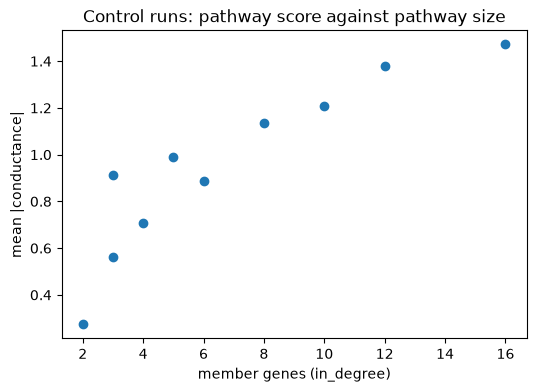

In [ ]:
mean_control = control.mean("seed").to_pandas()
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(
    counts.loc[mean_control.index, "in_degree"],
    mean_control,
)
ax.set_xlabel("member genes (in_degree)")
ax.set_ylabel("mean |conductance|")
ax.set_title("Control runs: pathway score against pathway size")
plt.show()

## Measuring it in your model

The check needs two things every `kpnn2` model has: scores named by
`map_node_attributions()`, and `node_table()`. Join them by node
name and correlate them layer by layer. `rank_correlation()` above
does that for any column of the table. In deeper layers, where a
node's parents are other pathways, `n_input_ancestors` counts the
genes that reach it through any path: its gene-set size in a
pathway hierarchy. Betweenness and other centralities are not in the
table; networkx computes them from `spec.to_edgelist()`.

Here the label shifts four genes. Several pathways of different
sizes contain them, so the data do not single out one pathway.

In [ ]:
informative = ["gene_01", "gene_02", "gene_03", "gene_04"]
real = runs(informative)
print(
    "runs on real data, rank correlation with in_degree:",
    rank_correlation(
        real,
        "in_degree",
    ),
)
informative_members = (
    edgelist[edgelist["source"].isin(informative)]
    .groupby("target")
    .size()
    .reindex(
        pathways,
        fill_value=0,
    )
)
pd.DataFrame(
    {
        "in_degree": counts.loc[pathways, "in_degree"],
        "informative_genes": informative_members,
    }
).T

runs on real data, rank correlation with in_degree: [0.97, 0.87, 0.94, 0.97, 0.9]


,pathway_a,pathway_b,pathway_c,pathway_d,pathway_e,pathway_f,pathway_g,pathway_h,pathway_i,pathway_j
in_degree,2,3,3,4,5,6,8,10,12,16
informative_genes,1,0,1,0,0,1,2,2,1,3


The correlations are as high as in the control runs, but here the
larger pathways also tend to hold more of the informative genes, as
the table shows. A correlation with size alone does not tell bias from
signal. The next two sections show corrections that try to separate
them, each with its own assumption.

## Correcting with structure counts

Elmarakeby et al. (2021) divide a node's score by its degree, the
number of its parents plus its children, when the score lies above
the mean plus five standard deviations of its layer. They count
degree from the trained weights that are not zero, which matches
the graph's edges unless a weight is exactly zero. The next cell
applies the division to every pathway; the five-standard-deviation
condition is one `Series.where()` on top.

In [ ]:
mean_real = real.mean("seed").to_pandas()
degree = (
    counts.loc[mean_real.index, "in_degree"]
    + counts.loc[mean_real.index, "out_degree"]
)
comparison = pd.DataFrame(
    {
        "in_degree": counts.loc[mean_real.index, "in_degree"],
        "raw": mean_real,
        "per_degree": mean_real / degree,
    }
)
comparison.round(3)

,in_degree,raw,per_degree
node,,,
pathway_a,2,0.250,0.083
pathway_b,3,0.394,0.098
pathway_c,3,0.288,0.072
pathway_d,4,0.508,0.102
pathway_e,5,0.506,0.084
pathway_f,6,0.647,0.092
pathway_g,8,1.007,0.112
pathway_h,10,1.087,0.099
pathway_i,12,1.354,0.104


## Correcting with control runs

Fortelny and Bock (2020) test each node's scores on real data
against its scores in control runs; the plainest form of that
comparison is a difference of means. Esser-Skala and Fortelny
(2023) first quantile-normalize the scores of all runs together, so
every run has the same distribution of scores, then subtract the
control mean. Their control runs are trained on shuffled labels;
the code takes any set of control runs.

Scores are keyed by node name, so the control runs may come from a
different spec, such as a randomized graph, as long as the node
names match.

In [ ]:
def quantile_normalize(table):
    # Every column gets the mean of the sorted columns.
    reference = np.sort(
        table.to_numpy(),
        axis=0,
    ).mean(axis=1)
    ranks = table.rank(method="first").astype(int) - 1
    return ranks.apply(
        lambda column: pd.Series(
            reference[column.to_numpy()],
            index=column.index,
        )
    )


all_runs = pd.concat(
    [
        real.to_pandas().T.add_prefix("real_"),
        control.to_pandas().T.add_prefix("control_"),
    ],
    axis=1,
)
normalized = quantile_normalize(all_runs)

comparison["minus_control"] = mean_real - mean_control
normalized_real = normalized.filter(like="real_").mean(axis=1)
normalized_control = normalized.filter(like="control_").mean(axis=1)
comparison["normalized_minus_control"] = normalized_real - normalized_control
comparison.round(3)

,in_degree,raw,per_degree,minus_control,normalized_minus_control
node,,,,,
pathway_a,2,0.250,0.083,-0.023,0.028
pathway_b,3,0.394,0.098,-0.518,-0.204
pathway_c,3,0.288,0.072,-0.274,0.022
pathway_d,4,0.508,0.102,-0.198,0.054
pathway_e,5,0.506,0.084,-0.485,-0.145
pathway_f,6,0.647,0.092,-0.242,0.161
pathway_g,8,1.007,0.112,-0.128,0.001
pathway_h,10,1.087,0.099,-0.123,0.040
pathway_i,12,1.354,0.104,-0.027,0.042


Without normalization the differences are mostly negative: in the
control runs every gene carries signal, so their scores run higher
across the board. Quantile normalization puts all runs on one scale
before the subtraction. The ranks make the versions easier to
compare: 1 is the top-scoring pathway in each.

In [ ]:
comparison.drop(columns="in_degree").rank(ascending=False).astype(int)

,raw,per_degree,minus_control,normalized_minus_control
node,,,,
pathway_a,10,9,2,5
pathway_b,8,5,10,10
pathway_c,9,10,8,6
pathway_d,6,3,6,2
pathway_e,7,8,9,9
pathway_f,5,6,7,1
pathway_g,4,1,5,7
pathway_h,3,4,4,4
pathway_i,2,2,3,3


The four versions order the pathways differently. The data do not
say which order is right: the label shifts four genes, and several
pathways of different sizes contain them. Each correction encodes
its own assumption about how much of a large pathway's score is
size rather than signal.

## Scaling inside the model

Some models change the forward pass so that a node's size sets the
scale of its value less. Kim and Lee (2023) divide each pathway's
pre-activation by the square root of its member count, and Zhang et
al. (2024) average over incoming edges. For either, `node_table()`
gives the counts in unit order: `np.repeat()` by the `width` column
turns a layer's rows into one value per unit, so the divisor also
fits nodes with several units.

In [ ]:
class ScaledPathwayModel(PathwayModel):
    def __init__(
        self,
        spec,
        generator,
    ):
        super().__init__(
            spec,
            generator,
        )
        table = spec.node_table()
        pathway_rows = table[table["layer"] == 1]
        member_count = np.repeat(
            pathway_rows["in_degree"].to_numpy(),
            pathway_rows["width"].to_numpy(),
        )
        self.register_buffer(
            "pathway_scale",
            torch.as_tensor(
                member_count,
                dtype=torch.float32,
            ).sqrt(),
        )

    def forward(self, x):
        pathway_state = torch.tanh(self.hops[0](x) / self.pathway_scale)
        return self.hops[1](pathway_state)


scaled = ScaledPathwayModel(
    spec,
    torch.Generator().manual_seed(0),
)
print(
    "divisor per pathway unit:",
    [
        round(
            value,
            2,
        )
        for value in scaled.pathway_scale.tolist()
    ],
)

divisor per pathway unit: [1.41, 1.73, 1.73, 2.0, 2.24, 2.45, 2.83, 3.16, 3.46, 4.0]


`runs(genes, model_class=ScaledPathwayModel)` repeats the control
check on this model.

## Before you correct

- **A correction is a modeling assumption.** Dividing by size
  assumes that a large node's extra score is an artifact. If large
  nodes matter, or the graph misses edges, the correction removes
  signal along with the artifact, and results can get worse.
- **Judge a correction by a criterion that does not depend on it:**
  a simulation whose ground truth you set, held-out data, or
  agreement with independent evidence. A toy as small as this
  page's says nothing about your data.
- **Use several runs.** Scores of single runs vary, as the
  per-run correlations above show. Esser-Skala and Fortelny (2023)
  retrain each network many times before they compare scores.
- **Report uncorrected scores next to corrected ones,** and name
  the correction.
- **Decide how a wide node combines its units.**
  `map_node_attributions()` repeats a wide node's name on each of
  its units and does not fold them. A sum over the units grows with
  the node's width, so when widths grow with degree, summing adds
  size back; a mean does not.

## What kpnn2 does not do

`kpnn2` does not simulate control data, shuffle labels, rewire a
graph, or choose a correction. It provides the parts each approach
needs: scores named by node (`map_node_attributions()`), graph
counts in unit order (`node_table()`), seeds isolated per run
(`generator=`), and a checkpoint check that stops a control model
from loading another prior's weights (`identity=spec.fingerprint`).
Folds of node scores that ship with `kpnn2` live in the method
registry of `aggregate_node_attributions()`;
`list_aggregation_methods()` lists them.

## References

- Elmarakeby HA, et al. (2021). Biologically
  informed deep neural network for prostate cancer discovery.
  *Nature* 598:348–352.
  [doi:10.1038/s41586-021-03922-4](https://doi.org/10.1038/s41586-021-03922-4)
- Esser-Skala W, Fortelny N (2023). Reliable interpretability of
  biology-inspired deep neural networks. *npj Systems Biology and
  Applications* 9:50.
  [doi:10.1038/s41540-023-00310-8](https://doi.org/10.1038/s41540-023-00310-8)
- Fortelny N, Bock C (2020). Knowledge-primed neural networks enable
  biologically interpretable deep learning on single-cell sequencing
  data. *Genome Biology* 21:190.
  [doi:10.1186/s13059-020-02100-5](https://doi.org/10.1186/s13059-020-02100-5)
- Kim Y, Lee H (2023). PINNet: a deep neural network with pathway
  prior knowledge for Alzheimer's disease. *Frontiers in Aging
  Neuroscience* 15:1126156.
  [doi:10.3389/fnagi.2023.1126156](https://doi.org/10.3389/fnagi.2023.1126156)
- Zhang H, Chen Y, Payne P, Li F (2024). Using DeepSignalingFlow to
  mine signaling flows interpreting mechanism of synergy of
  cocktails. *npj Systems Biology and Applications* 10:92.
  [doi:10.1038/s41540-024-00421-w](https://doi.org/10.1038/s41540-024-00421-w)